# Task 3: Customer Churn and Sales Trend Analysis
**InternCircle Data Science Internship** | **Author:** Vignesh Murugesan

**Objective:** Perform an end-to-end analysis of an e-commerce sales dataset to identify **top customer segments** and **revenue trends**, and turn the findings into **actionable business recommendations**.

**Dataset:** UCI *Online Retail* data, about 540,000 real transactions from a UK-based online gift retailer (1 Dec 2010 to 9 Dec 2011), with customers in 38 countries. The notebook downloads it automatically.

**Plan**
1. Load, inspect and clean the data
2. Feature engineering and date extraction
3. Revenue trend analysis (monthly, new vs returning, country, weekday and hour, products)
4. Customer segmentation with **RFM** (Recency, Frequency, Monetary)
5. Churn analysis and cohort retention
6. Business recommendations

## 1. Setup and load data

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from IPython.display import Markdown, display

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.spines.top": False, "axes.spines.right": False})
os.makedirs("figures", exist_ok=True)
os.makedirs("outputs", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"figures/{name}.png", dpi=150, bbox_inches="tight")

URL = "https://raw.githubusercontent.com/databricks/Spark-The-Definitive-Guide/master/data/retail-data/all/online-retail-dataset.csv"
raw = pd.read_csv(URL)
print("Rows, columns:", raw.shape)

Rows, columns: (541909, 8)


In [2]:
raw.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [4]:
raw.describe().round(2)

,Quantity,UnitPrice,CustomerID
count,541909.00,541909.00,406829.00
mean,9.55,4.61,15287.69
std,218.08,96.76,1713.60
min,-80995.00,-11062.06,12346.00
25%,1.00,1.25,13953.00
50%,3.00,2.08,15152.00
75%,10.00,4.13,16791.00
max,80995.00,38970.00,18287.00


**Data dictionary**

| Column | Meaning |
|---|---|
| InvoiceNo | Invoice number (starts with `C` for a cancellation) |
| StockCode / Description | Product code and name |
| Quantity, UnitPrice | Units sold and price per unit (pounds) |
| InvoiceDate | Date and time of the invoice |
| CustomerID | Customer identifier (missing for guest checkouts) |
| Country | Customer country |

## 2. Data cleaning

In [5]:
raw["InvoiceNo"] = raw["InvoiceNo"].astype(str)
raw["StockCode"] = raw["StockCode"].astype(str)
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], format="%m/%d/%Y %H:%M")

report = {
    "Raw rows": len(raw),
    "Cancellation invoices (start with C)": int(raw["InvoiceNo"].str.startswith("C").sum()),
    "Rows with Quantity <= 0": int((raw["Quantity"] <= 0).sum()),
    "Rows with UnitPrice <= 0": int((raw["UnitPrice"] <= 0).sum()),
    "Rows without CustomerID": int(raw["CustomerID"].isna().sum()),
    "Fully duplicated rows": int(raw.duplicated().sum()),
}
pd.Series(report, name="count").to_frame()

,count
Raw rows,541909
Cancellation invoices (start with C),9288
Rows with Quantity <= 0,10624
Rows with UnitPrice <= 0,2517
Rows without CustomerID,135080
Fully duplicated rows,5268


In [6]:
# Value of cancelled orders (kept aside as a KPI, not mixed into sales)
cancelled = raw[raw["InvoiceNo"].str.startswith("C") & (raw["Quantity"] > -50_000)]   # excludes the 2 giant same-day reversals
cancel_value = -(cancelled["Quantity"] * cancelled["UnitPrice"]).sum()

# Valid sales: no cancellations, positive quantity and price, no duplicates
sales = raw[~raw["InvoiceNo"].str.startswith("C") & (raw["Quantity"] > 0) & (raw["UnitPrice"] > 0)].drop_duplicates().copy()

# Two huge orders (74,215 and 80,995 units) were cancelled the same day. Keeping them would inflate revenue.
sales = sales[sales["Quantity"] < 50_000].copy()

# Revenue per line
sales["Revenue"] = sales["Quantity"] * sales["UnitPrice"]

# Customers analysis needs a CustomerID
cust = sales.dropna(subset=["CustomerID"]).copy()
cust["CustomerID"] = cust["CustomerID"].astype(int)

print(f"Valid sales rows         : {len(sales):,}  (from {len(raw):,})")
print(f"Rows with known customer : {len(cust):,}  ({len(cust)/len(sales):.1%})")
print(f"Revenue, all valid sales : {sales['Revenue'].sum():,.0f}")
print(f"Revenue, known customers : {cust['Revenue'].sum():,.0f}  ({cust['Revenue'].sum()/sales['Revenue'].sum():.1%})")
print(f"Value of cancelled orders: {cancel_value:,.0f}")

Valid sales rows         : 524,876  (from 541,909)
Rows with known customer : 392,690  (74.8%)
Revenue, all valid sales : 10,396,458
Revenue, known customers : 8,641,556  (83.1%)
Value of cancelled orders: 651,159


**Cleaning decisions**
- Cancellations, negative quantities and zero prices are removed from sales, and the cancelled value is tracked separately.
- Exact duplicate rows are dropped.
- Rows without `CustomerID` are kept for overall revenue trends but excluded from customer-level analysis (RFM, churn, cohorts), because they cannot be linked to a person.
- Two giant orders that were cancelled the same day are removed so they do not distort revenue.

## 3. Feature engineering and date extraction

In [7]:
def add_date_features(df):
    d = df["InvoiceDate"]
    df["Date"] = d.dt.date
    df["YearMonth"] = d.dt.to_period("M")
    df["Month"] = d.dt.month
    df["Quarter"] = d.dt.quarter
    df["DayName"] = d.dt.day_name()
    df["Hour"] = d.dt.hour
    return df

sales = add_date_features(sales)
cust = add_date_features(cust)

DAY_ORDER = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sales[["InvoiceDate", "YearMonth", "Quarter", "DayName", "Hour", "Quantity", "UnitPrice", "Revenue"]].head()

,InvoiceDate,YearMonth,Quarter,DayName,Hour,Quantity,UnitPrice,Revenue
0,2010-12-01 08:26:00,2010-12,4,Wednesday,8,6,2.55,15.30
1,2010-12-01 08:26:00,2010-12,4,Wednesday,8,6,3.39,20.34
2,2010-12-01 08:26:00,2010-12,4,Wednesday,8,8,2.75,22.00
3,2010-12-01 08:26:00,2010-12,4,Wednesday,8,6,3.39,20.34
4,2010-12-01 08:26:00,2010-12,4,Wednesday,8,6,3.39,20.34


In [8]:
# Non-product lines (postage, manual adjustments, fees) distort product rankings
NON_PRODUCT = ["POST", "DOT", "M", "BANK CHARGES", "CRUK", "C2", "D", "S", "AMAZONFEE", "B", "PADS"]
products = sales[~sales["StockCode"].isin(NON_PRODUCT) & ~sales["StockCode"].str.startswith("gift")]
print("Product lines kept:", len(products), "| non-product lines removed:", len(sales) - len(products))

Product lines kept: 522536 | non-product lines removed: 2340


## 4. Revenue trends

In [9]:
total_rev = sales["Revenue"].sum()
orders = sales["InvoiceNo"].nunique()
n_customers = cust["CustomerID"].nunique()
uk_share = sales.loc[sales["Country"] == "United Kingdom", "Revenue"].sum() / total_rev

kpis = pd.Series({
    "Total revenue (pounds)": f"{total_rev:,.0f}",
    "Orders": f"{orders:,}",
    "Identified customers": f"{n_customers:,}",
    "Average order value": f"{total_rev/orders:,.0f}",
    "Revenue from United Kingdom": f"{uk_share:.1%}",
    "Countries": sales["Country"].nunique(),
    "Cancelled order value": f"{cancel_value:,.0f}",
}, name="KPI").to_frame()
kpis

,KPI
Total revenue (pounds),"10,396,458"
Orders,"19,958"
Identified customers,"4,337"
Average order value,521
Revenue from United Kingdom,84.2%
Countries,38
Cancelled order value,"651,159"


### 4.1 Monthly revenue, orders, customers and growth

In [10]:
monthly = sales.groupby("YearMonth").agg(
    revenue=("Revenue", "sum"),
    orders=("InvoiceNo", "nunique"),
    customers=("CustomerID", "nunique"),
).assign(aov=lambda x: x["revenue"] / x["orders"])
monthly["mom_growth"] = monthly["revenue"].pct_change()

# The last month is incomplete (data ends on 9 Dec 2011), so we do not compare it
last_month = monthly.index.max()
monthly.loc[last_month, "mom_growth"] = np.nan
monthly.round(2).style.format({"revenue": "{:,.0f}", "aov": "{:,.0f}", "mom_growth": "{:.1%}"})

,revenue,orders,customers,aov,mom_growth
YearMonth,,,,,
2010-12,"821,453",1559,885,527,nan%
2011-01,"612,628",1085,740,565,-25.0%
2011-02,"522,546",1100,758,475,-15.0%
2011-03,"716,215",1454,974,493,37.0%
2011-04,"536,968",1246,856,431,-25.0%
2011-05,"769,297",1681,1056,458,43.0%
2011-06,"760,547",1533,991,496,-1.0%
2011-07,"718,076",1475,949,487,-6.0%
2011-08,"757,841",1361,935,557,6.0%


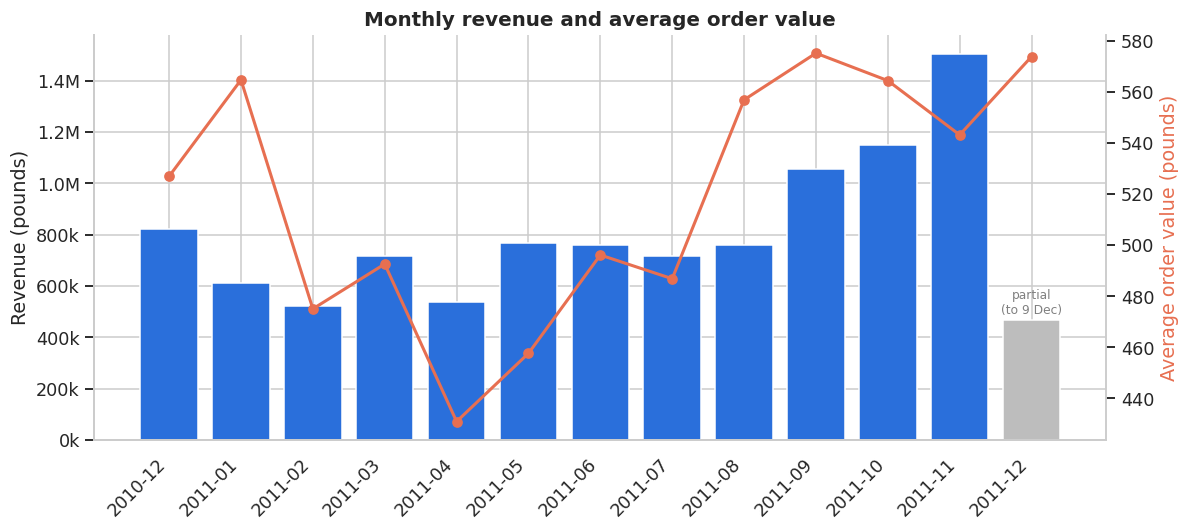

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
x = monthly.index.astype(str)
colors = ["#bdbdbd" if m == last_month else "#2a6fdb" for m in monthly.index]
ax.bar(x, monthly["revenue"], color=colors)
ax.set(title="Monthly revenue and average order value", ylabel="Revenue (pounds)")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M" if v >= 1e6 else f"{v/1e3:.0f}k"))
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
ax2 = ax.twinx()
ax2.plot(x, monthly["aov"], color="#e76f51", marker="o", lw=2)
ax2.set_ylabel("Average order value (pounds)", color="#e76f51")
ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.text(len(x) - 1, monthly["revenue"].iloc[-1] + 25000, "partial\n(to 9 Dec)", ha="center", fontsize=8, color="gray")
save("01_monthly_revenue_aov")
plt.show()

### 4.2 New vs returning customers (revenue)

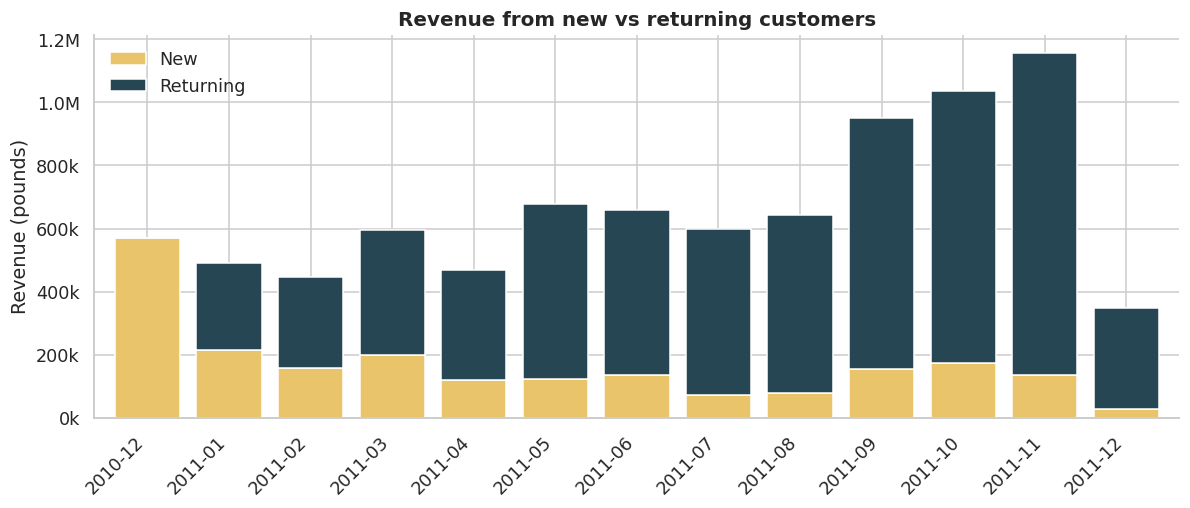

YearMonth,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12
returning_share,NaN,0.562,0.646,0.664,0.74,0.817,0.795,0.877,0.876,0.837,0.833,0.883,0.923


In [12]:
first_month = cust.groupby("CustomerID")["InvoiceDate"].transform("min").dt.to_period("M")
cust["CustomerType"] = np.where(cust["YearMonth"] == first_month, "New", "Returning")

type_rev = cust.pivot_table(values="Revenue", index="YearMonth", columns="CustomerType", aggfunc="sum")
type_rev["returning_share"] = type_rev["Returning"] / (type_rev["New"].fillna(0) + type_rev["Returning"])

ax = type_rev[["New", "Returning"]].plot(kind="bar", stacked=True, figsize=(11, 4.8), color=["#e9c46a", "#264653"], width=0.8)
ax.set(title="Revenue from new vs returning customers", xlabel="", ylabel="Revenue (pounds)")
ax.set_xticklabels([str(i) for i in type_rev.index], rotation=45, ha="right")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M" if v >= 1e6 else f"{v/1e3:.0f}k"))
ax.legend(title="", frameon=False)
save("02_new_vs_returning_revenue")
plt.show()
type_rev["returning_share"].round(3).to_frame().T

### 4.3 Revenue by country (pivot table)

In [13]:
country_rev = sales.groupby("Country")["Revenue"].sum().sort_values(ascending=False)
top_countries = country_rev.head(8)
print((top_countries / total_rev).round(3).to_string())

top5_non_uk = country_rev.drop("United Kingdom").head(5).index
country_month = sales[sales["Country"].isin(top5_non_uk)].pivot_table(
    values="Revenue", index="Country", columns="YearMonth", aggfunc="sum", fill_value=0).round(0)
country_month

Country
United Kingdom    0.842
Netherlands       0.027
EIRE              0.027
Germany           0.022
France            0.020
Australia         0.013
Spain             0.006
Switzerland       0.005


YearMonth,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11,2011-12
Country,,,,,,,,,,,,,
Australia,965.0,9018.0,14695.0,17224.0,772.0,13638.0,25188.0,4964.0,22489.0,5107.0,17151.0,7243.0,0.0
EIRE,10033.0,21904.0,12204.0,22198.0,7570.0,18004.0,24864.0,42739.0,18344.0,42924.0,24303.0,30713.0,7341.0
France,9616.0,17740.0,8516.0,14585.0,5530.0,17606.0,16348.0,10000.0,13811.0,23428.0,33471.0,31696.0,7277.0
Germany,15206.0,16881.0,9581.0,14393.0,12316.0,25735.0,13246.0,16441.0,19221.0,18079.0,31628.0,27968.0,7984.0
Netherlands,8784.0,26611.0,23012.0,22416.0,2977.0,29186.0,26858.0,26.0,40328.0,26937.0,40709.0,25874.0,11728.0


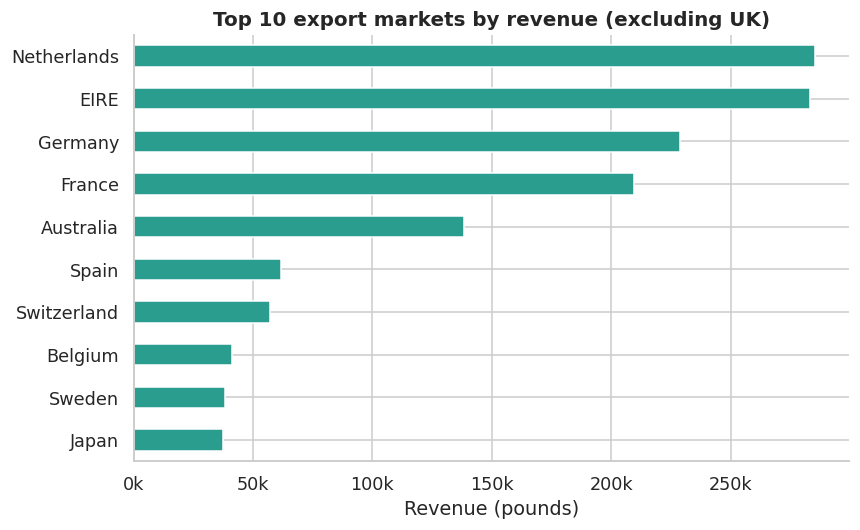

In [14]:
ax = country_rev.drop("United Kingdom").head(10).sort_values().plot(kind="barh", color="#2a9d8f", figsize=(8, 5))
ax.set(title="Top 10 export markets by revenue (excluding UK)", xlabel="Revenue (pounds)", ylabel="")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e3:.0f}k"))
save("03_top_export_markets")
plt.show()

### 4.4 When do customers buy? (weekday x hour)

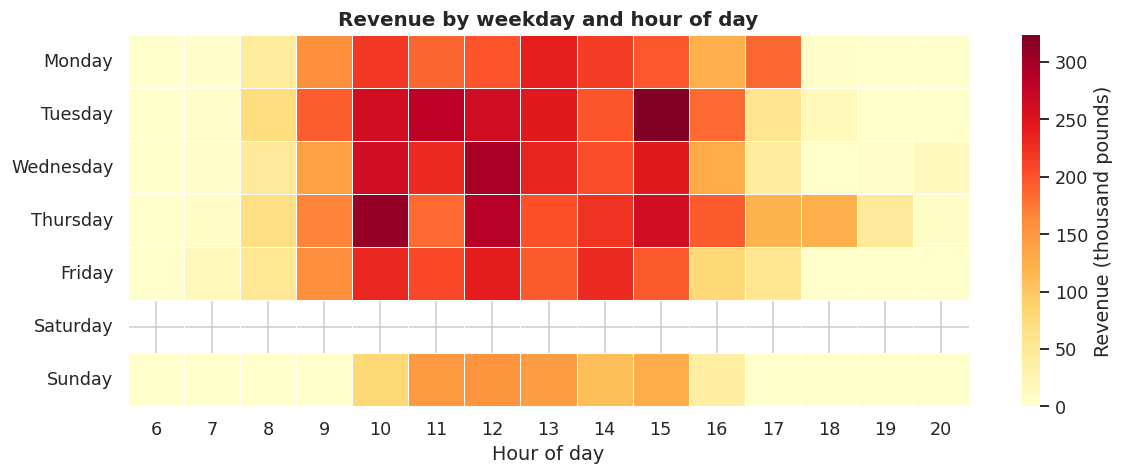

DayName,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
revenue,1775782.0,2098517.0,1847074.0,2199293.0,1669001.0,NaN,806791.0


In [15]:
wh = sales.pivot_table(values="Revenue", index="DayName", columns="Hour", aggfunc="sum", fill_value=0).reindex(DAY_ORDER)

plt.figure(figsize=(11, 4.5))
sns.heatmap(wh / 1000, cmap="YlOrRd", linewidths=0.4, cbar_kws={"label": "Revenue (thousand pounds)"})
plt.title("Revenue by weekday and hour of day")
plt.xlabel("Hour of day"); plt.ylabel("")
save("04_weekday_hour_heatmap")
plt.show()

by_day = sales.groupby("DayName")["Revenue"].sum().reindex(DAY_ORDER)
by_day.round(0).to_frame("revenue").T

### 4.5 Top products

,revenue,units,orders
Description,,,
REGENCY CAKESTAND 3 TIER,174157.0,13851,1988
WHITE HANGING HEART T-LIGHT HOLDER,106237.0,37872,2256
PARTY BUNTING,99445.0,18283,1685
JUMBO BAG RED RETROSPOT,94160.0,48371,2089
RABBIT NIGHT LIGHT,66870.0,30739,994
PAPER CHAIN KIT 50'S CHRISTMAS,64876.0,19329,1160
ASSORTED COLOUR BIRD ORNAMENT,58928.0,36362,1455
CHILLI LIGHTS,54096.0,10302,661
SPOTTY BUNTING,42513.0,8320,1140


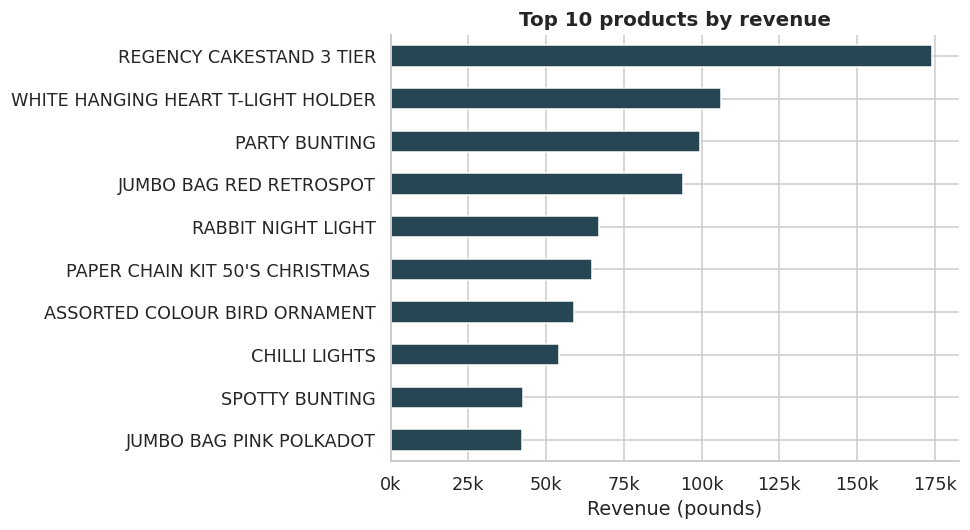

In [16]:
top_products = products.groupby("Description").agg(revenue=("Revenue", "sum"), units=("Quantity", "sum"), orders=("InvoiceNo", "nunique")).sort_values("revenue", ascending=False)
display(top_products.head(10).round(0))

ax = top_products["revenue"].head(10).sort_values().plot(kind="barh", color="#264653", figsize=(9, 5))
ax.set(title="Top 10 products by revenue", xlabel="Revenue (pounds)", ylabel="")
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e3:.0f}k"))
save("05_top_products")
plt.show()

## 5. Customer segmentation with RFM

**RFM** scores each customer on three behaviours:
- **Recency:** days since the last purchase (lower is better)
- **Frequency:** number of distinct orders (higher is better)
- **Monetary:** total spend (higher is better)

Each is scored 1 to 5 with quintiles, and customers are grouped into business-friendly segments.

In [17]:
snapshot = cust["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = cust.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda s: (snapshot - s.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    Country=("Country", "first"),
)

rfm["R"] = pd.qcut(rfm["Recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.qcut(rfm["Frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["Monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(row):
    if row.R >= 4 and row.F >= 4: return "Champions"
    if row.R >= 3 and row.F >= 3: return "Loyal"
    if row.R >= 4 and row.F <= 2: return "New / Promising"
    if row.R <= 2 and row.F >= 3: return "At Risk"
    if row.R <= 2 and row.F <= 2: return "Hibernating / Lost"
    return "Need Attention"

rfm["Segment"] = rfm.apply(segment, axis=1)
rfm.head()

,Recency,Frequency,Monetary,Country,R,F,M,Segment
CustomerID,,,,,,,,
12347,2,7,4310.00,Iceland,5,5,5,Champions
12348,75,4,1797.24,Finland,2,4,4,At Risk
12349,18,1,1757.55,Italy,4,1,4,New / Promising
12350,310,1,334.40,Norway,1,1,2,Hibernating / Lost
12352,36,8,2506.04,Norway,3,5,5,Loyal


In [18]:
seg = rfm.groupby("Segment").agg(
    customers=("Monetary", "size"),
    revenue=("Monetary", "sum"),
    avg_spend=("Monetary", "mean"),
    median_recency_days=("Recency", "median"),
    avg_orders=("Frequency", "mean"),
)
seg["customer_share"] = seg["customers"] / seg["customers"].sum()
seg["revenue_share"] = seg["revenue"] / seg["revenue"].sum()
seg = seg.sort_values("revenue", ascending=False)
seg.style.format({"revenue": "{:,.0f}", "avg_spend": "{:,.0f}", "median_recency_days": "{:.0f}", "avg_orders": "{:.1f}",
                  "customer_share": "{:.1%}", "revenue_share": "{:.1%}"})

,customers,revenue,avg_spend,median_recency_days,avg_orders,customer_share,revenue_share
Segment,,,,,,,
Champions,1128,"5,873,242","5,207",10,10.0,26.0%,68.0%
Loyal,818,"1,204,082","1,472",38,3.7,18.9%,13.9%
At Risk,656,"816,762","1,245",134,3.4,15.1%,9.5%
Hibernating / Lost,1071,"445,070",416,218,1.1,24.7%,5.2%
Need Attention,352,"165,402",470,52,1.2,8.1%,1.9%
New / Promising,312,"136,997",439,18,1.2,7.2%,1.6%


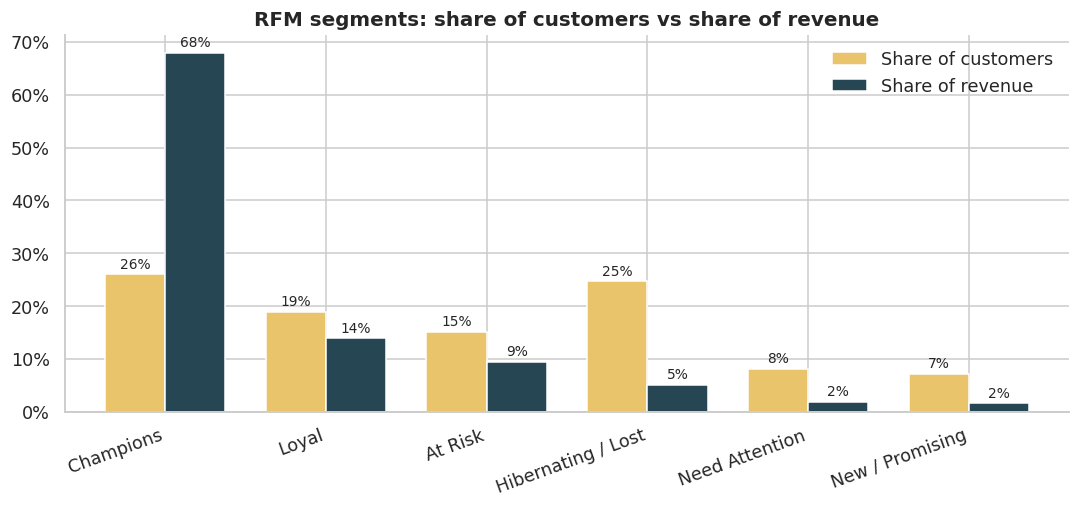

In [19]:
order = seg.index.tolist()
share = seg[["customer_share", "revenue_share"]].rename(columns={"customer_share": "Share of customers", "revenue_share": "Share of revenue"})

ax = share.plot(kind="bar", figsize=(10, 4.8), color=["#e9c46a", "#264653"], width=0.75)
ax.set(title="RFM segments: share of customers vs share of revenue", xlabel="", ylabel="")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xticklabels(order, rotation=20, ha="right")
for c in ax.containers:
    ax.bar_label(c, labels=[f"{v.get_height():.0%}" for v in c], padding=2, fontsize=9)
ax.legend(frameon=False)
save("06_rfm_segments_share")
plt.show()

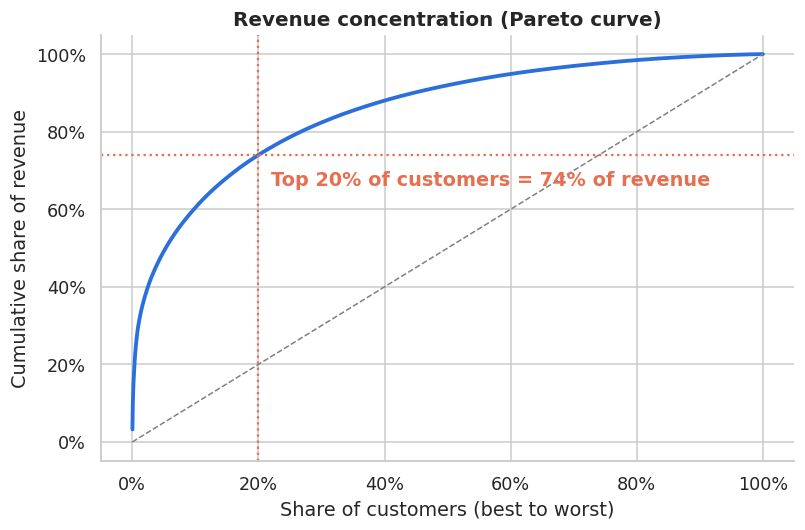

In [20]:
# Pareto: how concentrated is revenue?
spend = rfm["Monetary"].sort_values(ascending=False).reset_index(drop=True)
cum_rev = spend.cumsum() / spend.sum()
cum_cust = (np.arange(1, len(spend) + 1)) / len(spend)

top20_share = cum_rev[int(len(spend) * 0.2) - 1]
plt.figure(figsize=(7.5, 5))
plt.plot(cum_cust, cum_rev, color="#2a6fdb", lw=2.5)
plt.plot([0, 1], [0, 1], "--", color="gray", lw=1)
plt.axvline(0.2, color="#e76f51", ls=":"); plt.axhline(top20_share, color="#e76f51", ls=":")
plt.text(0.22, top20_share - 0.08, f"Top 20% of customers = {top20_share:.0%} of revenue", color="#e76f51", fontweight="bold")
plt.gca().xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); plt.gca().yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.title("Revenue concentration (Pareto curve)")
plt.xlabel("Share of customers (best to worst)"); plt.ylabel("Cumulative share of revenue")
save("07_pareto_customers")
plt.show()

In [21]:
# Top 10 customers
rfm.sort_values("Monetary", ascending=False).head(10)[["Country", "Recency", "Frequency", "Monetary", "Segment"]].round(0)

,Country,Recency,Frequency,Monetary,Segment
CustomerID,,,,,
14646,Netherlands,1,73,280206.0,Champions
18102,United Kingdom,0,60,259657.0,Champions
17450,United Kingdom,8,46,194391.0,Champions
14911,EIRE,1,201,143711.0,Champions
12415,Australia,24,21,124915.0,Champions
14156,EIRE,9,55,117210.0,Champions
17511,United Kingdom,2,31,91062.0,Champions
16029,United Kingdom,38,63,80851.0,Loyal
16684,United Kingdom,4,28,66654.0,Champions


## 6. Churn analysis

**Definition (no data leakage):** I look at customers who bought **before 1 Sep 2011** and label a customer as **churned** if they made **no purchase from 1 Sep to 9 Dec 2011** (about 100 days). Behaviour features are calculated only from the period before 1 Sep, so we can see which behaviours *predict* churn.

In [22]:
cutoff = pd.Timestamp("2011-09-01")
past = cust[cust["InvoiceDate"] < cutoff]
future_buyers = set(cust.loc[cust["InvoiceDate"] >= cutoff, "CustomerID"])

churn = past.groupby("CustomerID").agg(
    last_purchase=("InvoiceDate", "max"),
    first_purchase=("InvoiceDate", "min"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum"),
    Country=("Country", "first"),
)
churn["Recency"] = (cutoff - churn["last_purchase"]).dt.days
churn["Tenure"] = (cutoff - churn["first_purchase"]).dt.days
churn["Churned"] = (~churn.index.isin(future_buyers)).astype(int)

churn_rate = churn["Churned"].mean()
lost_value = churn.loc[churn["Churned"] == 1, "Monetary"].sum()
print(f"Customers active before 1 Sep 2011: {len(churn):,}")
print(f"Churn rate (no purchase in next ~100 days): {churn_rate:.1%}")
print(f"Past spend of churned customers: {lost_value:,.0f} ({lost_value/churn['Monetary'].sum():.1%} of all past spend)")

Customers active before 1 Sep 2011: 3,316
Churn rate (no purchase in next ~100 days): 41.2%
Past spend of churned customers: 879,321 (17.1% of all past spend)


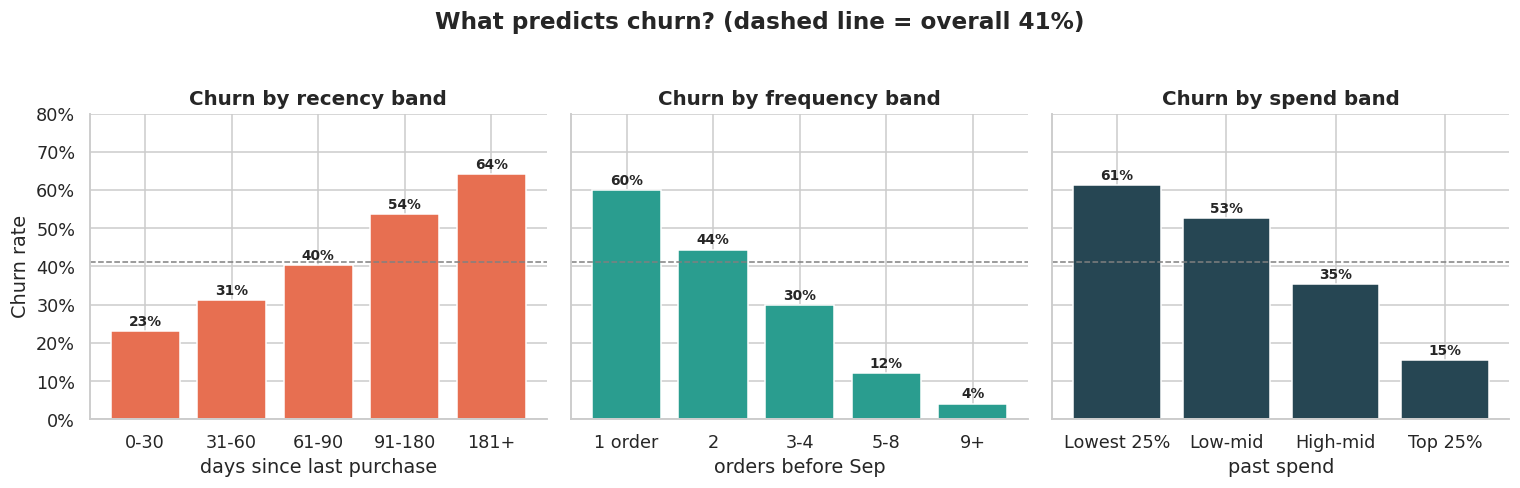

In [23]:
churn["Recency band"] = pd.cut(churn["Recency"], [-1, 30, 60, 90, 180, 400], labels=["0-30", "31-60", "61-90", "91-180", "181+"])
churn["Frequency band"] = pd.cut(churn["Frequency"], [0, 1, 2, 4, 8, 500], labels=["1 order", "2", "3-4", "5-8", "9+"])
churn["Spend band"] = pd.qcut(churn["Monetary"], 4, labels=["Lowest 25%", "Low-mid", "High-mid", "Top 25%"])

fig, axes = plt.subplots(1, 3, figsize=(14, 4.3), sharey=True)
for ax, col, color in zip(axes, ["Recency band", "Frequency band", "Spend band"], ["#e76f51", "#2a9d8f", "#264653"]):
    r = churn.groupby(col, observed=True)["Churned"].mean()
    ax.bar(r.index.astype(str), r.values, color=color)
    ax.axhline(churn_rate, color="gray", ls="--", lw=1)
    for i, v in enumerate(r.values):
        ax.text(i, v + 0.015, f"{v:.0%}", ha="center", fontsize=9, fontweight="bold")
    ax.set(title=f"Churn by {col.lower()}", xlabel=("days since last purchase" if col.startswith("Rec") else "orders before Sep" if col.startswith("Freq") else "past spend"))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_ylim(0, 0.8)
axes[0].set_ylabel("Churn rate")
fig.suptitle(f"What predicts churn? (dashed line = overall {churn_rate:.0%})", fontweight="bold", y=1.03)
save("08_churn_drivers")
plt.show()

In [24]:
# Pivot: churn rate by frequency band and recency band
churn.pivot_table(values="Churned", index="Frequency band", columns="Recency band", aggfunc="mean", observed=True).round(2)

Recency band,0-30,31-60,61-90,91-180,181+
Frequency band,,,,,
1 order,0.49,0.53,0.55,0.62,0.65
2,0.35,0.40,0.43,0.50,0.57
3-4,0.29,0.25,0.28,0.36,0.50
5-8,0.11,0.06,0.18,0.19,0.71
9+,0.02,0.06,0.29,1.00,1.00


In [25]:
churn[["Recency", "Frequency", "Monetary", "Tenure", "Churned"]].corr()["Churned"].drop("Churned").round(2).to_frame("correlation with churn")

,correlation with churn
Recency,0.31
Frequency,-0.25
Monetary,-0.13
Tenure,-0.14


## 7. Cohort retention

Customers are grouped by the month of their **first purchase**. The table shows the share of each cohort that bought again in later months. December 2011 is excluded because the data stops on 9 Dec.

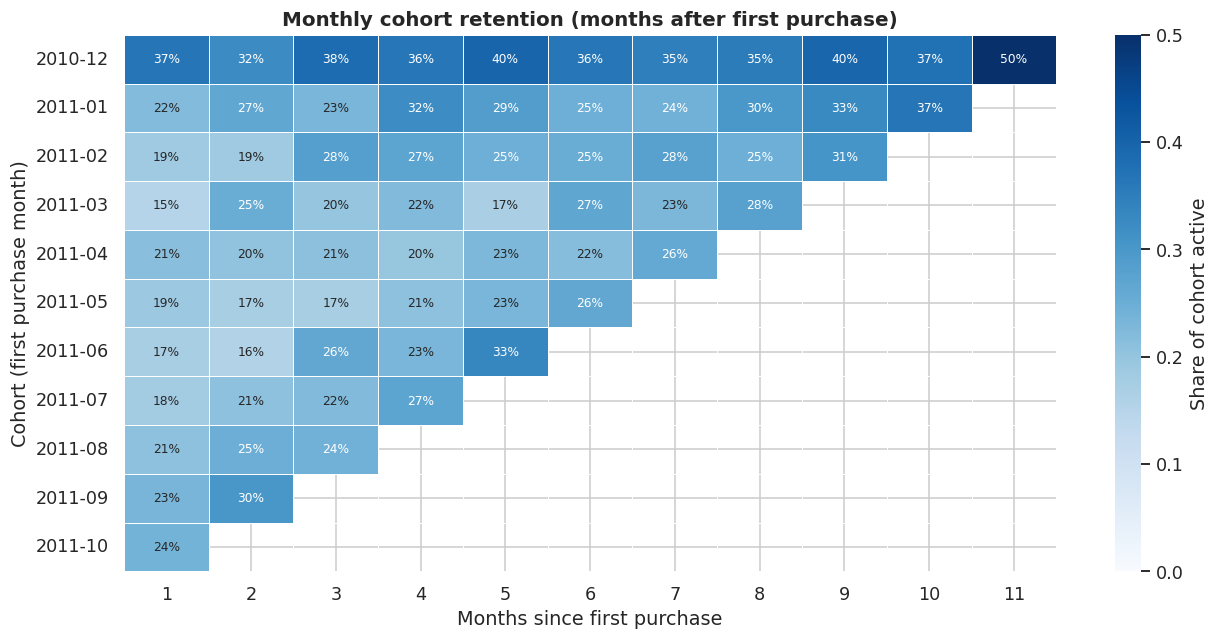

In [26]:
cust["Cohort"] = cust.groupby("CustomerID")["InvoiceDate"].transform("min").dt.to_period("M")
cust["CohortIndex"] = (cust["YearMonth"] - cust["Cohort"]).apply(lambda x: x.n)

# December 2011 is only partly observed (data ends 9 Dec), so it is left out to avoid fake drops in the last diagonal
cohort_data = cust[cust["YearMonth"] < pd.Period("2011-12")]
cohort_counts = cohort_data.groupby(["Cohort", "CohortIndex"])["CustomerID"].nunique().unstack()
retention = cohort_counts.div(cohort_counts[0], axis=0)
retention = retention.drop(index=retention.index.max())   # the last cohort (Nov 2011) has no later month to measure

plt.figure(figsize=(12, 6))
sns.heatmap(retention.iloc[:, 1:], annot=True, fmt=".0%", cmap="Blues", vmin=0, vmax=0.5, linewidths=0.4,
            cbar_kws={"label": "Share of cohort active"}, annot_kws={"size": 8})
plt.title("Monthly cohort retention (months after first purchase)")
plt.xlabel("Months since first purchase"); plt.ylabel("Cohort (first purchase month)")
save("09_cohort_retention")
plt.show()

In [27]:
cohort_sizes = cohort_counts[0].rename("new customers")
avg_m1 = retention[1].iloc[1:].mean()   # skip Dec-2010 cohort: it also contains customers who joined before the data starts
print(f"Average month-1 retention (cohorts Jan to Oct 2011): {avg_m1:.1%}")
cohort_sizes.to_frame().T

Average month-1 retention (cohorts Jan to Oct 2011): 20.0%


Cohort,2010-12,2011-01,2011-02,2011-03,2011-04,2011-05,2011-06,2011-07,2011-08,2011-09,2011-10,2011-11
new customers,885.0,416.0,380.0,452.0,300.0,284.0,242.0,188.0,169.0,299.0,358.0,323.0


## 8. Key insights (calculated from the data above)

In [28]:
complete = monthly.drop(index=last_month)
best_m = complete["revenue"].idxmax(); worst_m = complete["revenue"].idxmin()
q4 = complete.loc[pd.Period("2011-09"):pd.Period("2011-11"), "revenue"].sum() / complete["revenue"].sum()
best_day = by_day.idxmax()
hour_rev = sales.groupby("Hour")["Revenue"].sum()
peak_hours = hour_rev.loc[10:15].sum() / hour_rev.sum()
champ = seg.loc["Champions"]; risk = seg.loc["At Risk"]; lost = seg.loc["Hibernating / Lost"]
one_time = churn.loc[churn["Frequency"] == 1, "Churned"].mean()
loyal_f = churn.loc[churn["Frequency"] >= 9, "Churned"].mean()
stale = churn.loc[churn["Recency"] > 90, "Churned"].mean()
fresh = churn.loc[churn["Recency"] <= 30, "Churned"].mean()
ret_share = type_rev["returning_share"].iloc[1:].mean()
repeat_rate = (rfm["Frequency"] > 1).mean()

insights = f'''
1. **Overall:** {total_rev:,.0f} pounds revenue from {orders:,} orders and {n_customers:,} identified customers. Average order value is about {total_rev/orders:,.0f} pounds, which suggests that many customers are businesses or resellers rather than single shoppers.
2. **Strong seasonality:** revenue peaks in **{best_m}** ({complete.loc[best_m,'revenue']:,.0f}) and is lowest in **{worst_m}** ({complete.loc[worst_m,'revenue']:,.0f}). September to November alone bring **{q4:.0%}** of the revenue of the 12 complete months, driven by Christmas stock-up.
3. **Returning customers drive growth:** on average **{ret_share:.0%}** of monthly revenue comes from returning customers, and {repeat_rate:.0%} of customers ordered more than once.
4. **UK dependence:** the United Kingdom provides **{uk_share:.0%}** of revenue. Netherlands, EIRE, Germany and France are the biggest export markets.
5. **Buying pattern:** {best_day} is the best weekday, there are **no Saturday sales**, and **{peak_hours:.0%}** of revenue arrives between 10:00 and 15:59.
6. **Customer concentration:** the top 20% of customers produce **{top20_share:.0%}** of revenue. **Champions** are only {champ['customer_share']:.0%} of customers but bring **{champ['revenue_share']:.0%}** of revenue (about {champ['avg_spend']:,.0f} pounds each).
7. **Revenue at risk:** the **At Risk** segment ({int(risk['customers'])} customers) holds {risk['revenue']:,.0f} pounds of past spend and has not bought for about {risk['median_recency_days']:.0f} days. **Hibernating / Lost** customers ({lost['customer_share']:.0%} of the base) contribute only {lost['revenue_share']:.0%} of revenue.
8. **Churn is {churn_rate:.0%}** over the final ~100 days. It is predictable: customers with **one order churn at {one_time:.0%}** versus **{loyal_f:.0%}** for customers with 9 or more orders, and customers silent for more than 90 days churn at **{stale:.0%}** versus **{fresh:.0%}** for those active in the last 30 days.
9. **Retention is weak after the first order:** only about **{avg_m1:.0%}** of a new cohort buys again in the following month.
'''
display(Markdown(insights))


1. **Overall:** 10,396,458 pounds revenue from 19,958 orders and 4,337 identified customers. Average order value is about 521 pounds, which suggests that many customers are businesses or resellers rather than single shoppers.
2. **Strong seasonality:** revenue peaks in **2011-11** (1,503,867) and is lowest in **2011-02** (522,546). September to November alone bring **37%** of the revenue of the 12 complete months, driven by Christmas stock-up.
3. **Returning customers drive growth:** on average **79%** of monthly revenue comes from returning customers, and 66% of customers ordered more than once.
4. **UK dependence:** the United Kingdom provides **84%** of revenue. Netherlands, EIRE, Germany and France are the biggest export markets.
5. **Buying pattern:** Thursday is the best weekday, there are **no Saturday sales**, and **75%** of revenue arrives between 10:00 and 15:59.
6. **Customer concentration:** the top 20% of customers produce **74%** of revenue. **Champions** are only 26% of customers but bring **68%** of revenue (about 5,207 pounds each).
7. **Revenue at risk:** the **At Risk** segment (656 customers) holds 816,762 pounds of past spend and has not bought for about 134 days. **Hibernating / Lost** customers (25% of the base) contribute only 5% of revenue.
8. **Churn is 41%** over the final ~100 days. It is predictable: customers with **one order churn at 60%** versus **4%** for customers with 9 or more orders, and customers silent for more than 90 days churn at **58%** versus **23%** for those active in the last 30 days.
9. **Retention is weak after the first order:** only about **20%** of a new cohort buys again in the following month.


## 9. Actionable business recommendations

In [29]:
recs = f'''
| # | Recommendation | Evidence | Expected impact |
|---|----------------|----------|-----------------|
| 1 | **Protect Champions** with a VIP programme: early access to new stock, volume discounts, a dedicated account contact | {champ['customer_share']:.0%} of customers generate {champ['revenue_share']:.0%} of revenue | Safeguards the largest revenue pool |
| 2 | **Win back At Risk customers** with a personal email or call and a time-limited offer when a customer passes about 60 days without an order | {int(risk['customers'])} customers, {risk['revenue']:,.0f} pounds past spend, churn climbs sharply after 60 to 90 days | Recovers high-value buyers before they are lost |
| 3 | **Convert one-time buyers into repeat buyers:** welcome series, second-order discount, product bundles | One-order customers churn at {one_time:.0%}; month-1 retention is only {avg_m1:.0%} | Biggest lever on retention |
| 4 | **Prepare for the Sep to Nov peak:** build stock earlier, run pre-season campaigns and staff for the peak | {q4:.0%} of annual revenue arrives in three months | Fewer stock-outs, more peak revenue |
| 5 | **Lift the slow months** (Jan to Apr) with promotions for trade customers, clearance and new-range launches | Lowest month was {worst_m} | Smoother cash flow |
| 6 | **Time campaigns** for weekday mornings to mid-afternoon and test a Saturday offer | {peak_hours:.0%} of revenue between 10:00 and 15:59; zero Saturday sales | Better campaign response, new revenue slot |
| 7 | **Grow export markets** (Netherlands, EIRE, Germany, France) with local shipping and wholesale offers | UK = {uk_share:.0%} of revenue | Lower dependence on one market |
| 8 | **Improve tracking:** encourage account creation or order-linked IDs at checkout | {1 - cust['Revenue'].sum()/sales['Revenue'].sum():.0%} of revenue has no CustomerID | Better segmentation and churn prediction |
| 9 | **Reduce cancellations** by checking large orders and improving product information | Cancelled orders total about {cancel_value:,.0f} pounds | Protects margin |
'''
display(Markdown(recs))


| # | Recommendation | Evidence | Expected impact |
|---|----------------|----------|-----------------|
| 1 | **Protect Champions** with a VIP programme: early access to new stock, volume discounts, a dedicated account contact | 26% of customers generate 68% of revenue | Safeguards the largest revenue pool |
| 2 | **Win back At Risk customers** with a personal email or call and a time-limited offer when a customer passes about 60 days without an order | 656 customers, 816,762 pounds past spend, churn climbs sharply after 60 to 90 days | Recovers high-value buyers before they are lost |
| 3 | **Convert one-time buyers into repeat buyers:** welcome series, second-order discount, product bundles | One-order customers churn at 60%; month-1 retention is only 20% | Biggest lever on retention |
| 4 | **Prepare for the Sep to Nov peak:** build stock earlier, run pre-season campaigns and staff for the peak | 37% of annual revenue arrives in three months | Fewer stock-outs, more peak revenue |
| 5 | **Lift the slow months** (Jan to Apr) with promotions for trade customers, clearance and new-range launches | Lowest month was 2011-02 | Smoother cash flow |
| 6 | **Time campaigns** for weekday mornings to mid-afternoon and test a Saturday offer | 75% of revenue between 10:00 and 15:59; zero Saturday sales | Better campaign response, new revenue slot |
| 7 | **Grow export markets** (Netherlands, EIRE, Germany, France) with local shipping and wholesale offers | UK = 84% of revenue | Lower dependence on one market |
| 8 | **Improve tracking:** encourage account creation or order-linked IDs at checkout | 17% of revenue has no CustomerID | Better segmentation and churn prediction |
| 9 | **Reduce cancellations** by checking large orders and improving product information | Cancelled orders total about 651,159 pounds | Protects margin |


**Limitations**
- The data covers only 12 months, so seasonality cannot be confirmed over several years. December 2011 is incomplete.
- Churn is defined by 100 days of inactivity. Some customers buy only seasonally and may simply return later.
- Revenue is shown before costs, so profitability by segment is unknown.
- About 17% of revenue has no `CustomerID` and is excluded from the customer analysis.
- RFM segments and thresholds are rule-based choices and can be tuned.

**Skills demonstrated:** data cleaning, date feature extraction, pivot tables, trend and growth calculations, RFM segmentation, churn definition without leakage, cohort retention, business storytelling.

In [30]:
# Save useful outputs
monthly.to_csv("outputs/monthly_trend.csv")
seg.to_csv("outputs/rfm_segment_summary.csv")
rfm.to_csv("outputs/customer_rfm_segments.csv")
retention.to_csv("outputs/cohort_retention.csv")
print("Saved files:", os.listdir("outputs"))

Saved files: ['customer_rfm_segments.csv', 'cohort_retention.csv', 'monthly_trend.csv', 'rfm_segment_summary.csv']
